<a href="https://colab.research.google.com/github/sanketkandalkar46-del/dsa-pp/blob/main/Another_copy_of_Assignment_2_Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Group B
## Assignment 2

### Regression Techniques

### Import all the required libraries

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

### Load the Dataset into pandas dataframe.

In [ ]:
df = pd.read_csv("sample_data/california_housing_test.csv")

#### Read the first and last n rows of a dataset.

In [ ]:
df.head()


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-122.05,37.37,27.0,3885.0,661.0,1537.0,606.0,6.6085,344700.0
1,-118.30,34.26,43.0,1510.0,310.0,809.0,277.0,3.5990,176500.0
2,-117.81,33.78,27.0,3589.0,507.0,1484.0,495.0,5.7934,270500.0
3,-118.36,33.82,28.0,67.0,15.0,49.0,11.0,6.1359,330000.0
4,-119.67,36.33,19.0,1241.0,244.0,850.0,237.0,2.9375,81700.0


In [ ]:
df.tail()


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
2995,-119.86,34.42,23.0,1450.0,642.0,1258.0,607.0,1.1790,225000.0
2996,-118.14,34.06,27.0,5257.0,1082.0,3496.0,1036.0,3.3906,237200.0
2997,-119.70,36.30,10.0,956.0,201.0,693.0,220.0,2.2895,62000.0
2998,-117.12,34.10,40.0,96.0,14.0,46.0,14.0,3.2708,162500.0
2999,-119.63,34.42,42.0,1765.0,263.0,753.0,260.0,8.5608,500001.0


#### Check the dimensions of the data frame

In [ ]:
df.shape

(3000, 9)

#### Print information about a DataFrame

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           3000 non-null   float64
 1   latitude            3000 non-null   float64
 2   housing_median_age  3000 non-null   float64
 3   total_rooms         3000 non-null   float64
 4   total_bedrooms      3000 non-null   float64
 5   population          3000 non-null   float64
 6   households          3000 non-null   float64
 7   median_income       3000 non-null   float64
 8   median_house_value  3000 non-null   float64
dtypes: float64(9)
memory usage: 211.1 KB


#### Provide descriptive statistics for dataset

In [ ]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,3000.000000,3000.00000,3000.000000,3000.000000,3000.000000,3000.000000,3000.00000,3000.000000,3000.00000
mean,-119.589200,35.63539,28.845333,2599.578667,529.950667,1402.798667,489.91200,3.807272,205846.27500
std,1.994936,2.12967,12.555396,2155.593332,415.654368,1030.543012,365.42271,1.854512,113119.68747
min,-124.180000,32.56000,1.000000,6.000000,2.000000,5.000000,2.00000,0.499900,22500.00000
25%,-121.810000,33.93000,18.000000,1401.000000,291.000000,780.000000,273.00000,2.544000,121200.00000
50%,-118.485000,34.27000,29.000000,2106.000000,437.000000,1155.000000,409.50000,3.487150,177650.00000
75%,-118.020000,37.69000,37.000000,3129.000000,636.000000,1742.750000,597.25000,4.656475,263975.00000
max,-114.490000,41.92000,52.000000,30450.000000,5419.000000,11935.000000,4930.00000,15.000100,500001.00000


#### Check for missing values in the data

In [ ]:
df.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,0
population,0
households,0
median_income,0
median_house_value,0


Handle Missing Values

In [ ]:
df['total_bedrooms']=df['total_bedrooms'].fillna(df['total_bedrooms'].median())

Encode Categorical Feature

In [ ]:
df.select_dtypes(include=['object', 'category']).columns

Index([], dtype='object')

### Exploratory Data Analysis

#### Find the pairwise correlation of all columns in the Dataframe

In [ ]:
df.corr()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
longitude,1.000000,-0.925017,-0.064203,0.049865,0.070869,0.111572,0.051062,-0.018701,-0.050662
latitude,-0.925017,1.000000,-0.025143,-0.039632,-0.068245,-0.117318,-0.068296,-0.072363,-0.138428
housing_median_age,-0.064203,-0.025143,1.000000,-0.367850,-0.323154,-0.299888,-0.305171,-0.144315,0.091409
total_rooms,0.049865,-0.039632,-0.367850,1.000000,0.937749,0.838867,0.914116,0.221249,0.160427
total_bedrooms,0.070869,-0.068245,-0.323154,0.937749,1.000000,0.856387,0.970758,0.024025,0.082279
population,0.111572,-0.117318,-0.299888,0.838867,0.856387,1.000000,0.895530,0.032361,-0.001192
households,0.051062,-0.068296,-0.305171,0.914116,0.970758,0.895530,1.000000,0.048625,0.100176
median_income,-0.018701,-0.072363,-0.144315,0.221249,0.024025,0.032361,0.048625,1.000000,0.672695
median_house_value,-0.050662,-0.138428,0.091409,0.160427,0.082279,-0.001192,0.100176,0.672695,1.000000


#### Generate a correlation heatmap

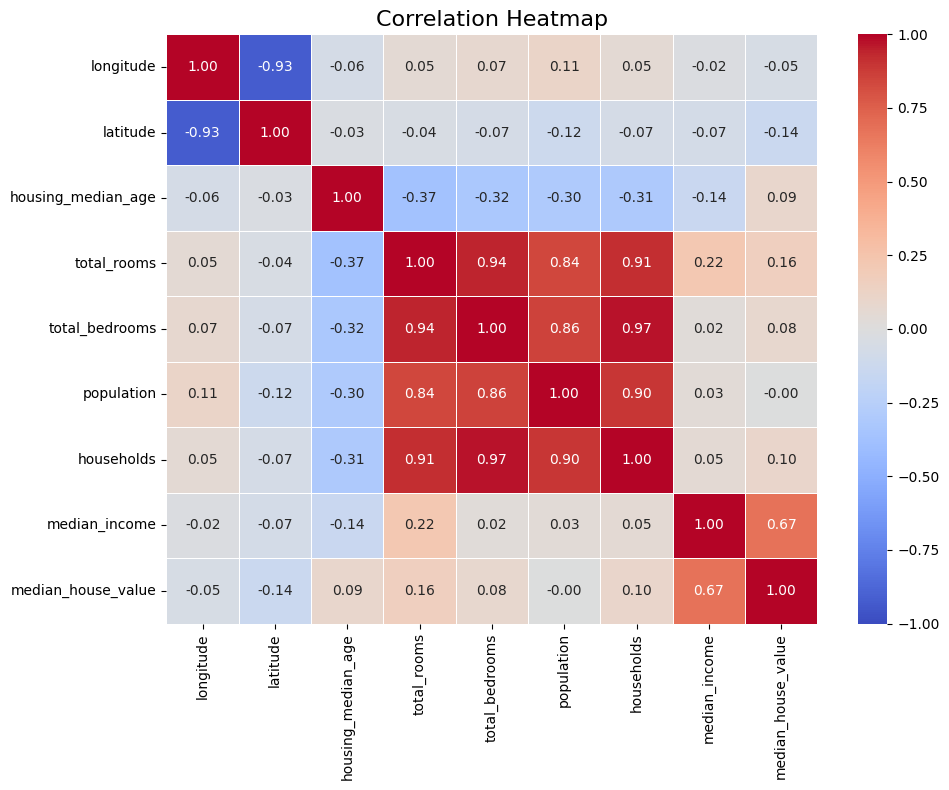

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate correlation between numeric columns
correlation = df.corr(numeric_only=True)

# Set figure size
plt.figure(figsize=(10, 8))

# Create heatmap
sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

# Add title
plt.title('Correlation Heatmap', fontsize=16)

# Display the plot
plt.tight_layout()
plt.show()

#### Display the relationship between two variables and observe the nature of the relationship.

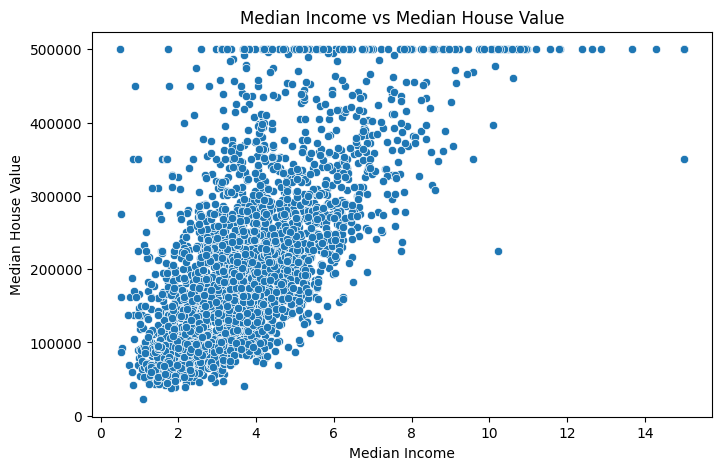

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='median_income',
    y='median_house_value'
)

plt.title('Median Income vs Median House Value')
plt.xlabel('Median Income')
plt.ylabel('Median House Value')
plt.show()

### Build Linear Regression Model

#### Extracting Independent and dependent Variable

In [ ]:
X = df.drop('median_house_value', axis=1)
y = df['median_house_value']

#### Splitting the dataset into training and test sets

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

#### Create Linear Regression model  

In [ ]:
linear_model = LinearRegression()

#### Fitting Linear Regression  model to the training set  

In [ ]:
linear_model.fit(X_train, y_train)

LinearRegression()

#### Predicting the test set result  

In [ ]:
y_pred = linear_model.predict(X_test)

#### Assess the performance of regression models using MSE, MAE and R-Square metrics

In [ ]:
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Linear Regression Performance")
print("Mean Squared Error (MSE):", mse)
print("Mean Absolute Error (MAE):", mae)
print("R-Squared (R2):", r2)

Linear Regression Performance
Mean Squared Error (MSE): 4586505886.68125
Mean Absolute Error (MAE): 49554.27620826821
R-Squared (R2): 0.6358044169850408


Polynomial Regression

generate polynomial features

In [ ]:
poly = PolynomialFeatures(degree=2, include_bias=False)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

Create the Polynomial Regression model

In [ ]:
poly_model = LinearRegression()

Fit the Polynomial Regression model

In [ ]:
poly_model.fit(X_train_poly, y_train)

LinearRegression()

Predict the test set results

In [ ]:
y_poly_pred = poly_model.predict(X_test_poly)

Assess Polynomial Regression using MSE, MAE and R-square

In [ ]:
poly_mse = mean_squared_error(y_test, y_poly_pred)
poly_mae = mean_absolute_error(y_test, y_poly_pred)
poly_r2 = r2_score(y_test, y_poly_pred)

print("Polynomial Regression Performance")
print("Mean Squared Error (MSE):", poly_mse)
print("Mean Absolute Error (MAE):", poly_mae)
print("R-Squared (R2):", poly_r2)

Polynomial Regression Performance
Mean Squared Error (MSE): 4994175208.853186
Mean Absolute Error (MAE): 45373.84804612915
R-Squared (R2): 0.6034330715351488


 Compare Linear and Polynomial Regression

In [ ]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Polynomial Regression'],
    'MSE': [mse, poly_mse],
    'MAE': [mae, poly_mae],
    'R2 Score': [r2, poly_r2]
})

print(results)

                   Model           MSE           MAE  R2 Score
0      Linear Regression  4.586506e+09  49554.276208  0.635804
1  Polynomial Regression  4.994175e+09  45373.848046  0.603433


Plot actual vs predicted house values

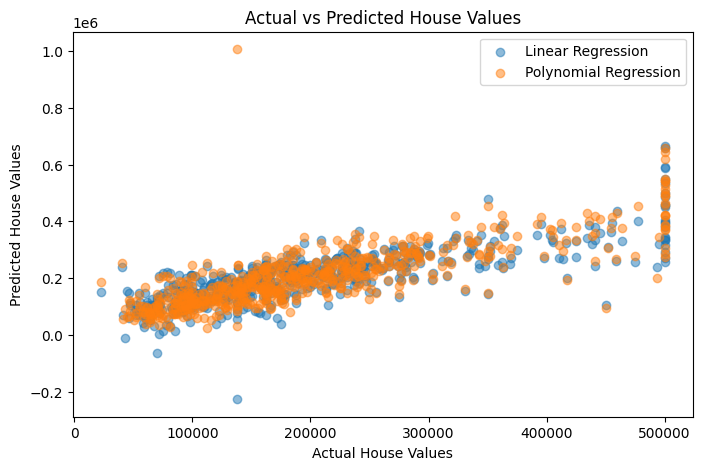

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.5, label='Linear Regression')
plt.scatter(y_test, y_poly_pred, alpha=0.5, label='Polynomial Regression')

plt.xlabel('Actual House Values')
plt.ylabel('Predicted House Values')
plt.title('Actual vs Predicted House Values')
plt.legend()
plt.show()